# Preprocessing choices - testing them on real recordings

Before writing the preprocessing layer of fastEIT (from the parsed `.bin` frames to a recording ready for
breath-by-breath analysis) I want to try the candidate methods on real data and choose with numbers in front
of me, not on paper. This notebook is where I do it: each section is a question, what I tried, and what I
decided. When a choice is settled the section stays here as the record of why.

There is no preprocessing code in fastEIT yet. As a reference I use
[eitprocessing](https://github.com/EIT-ALIVE/eitprocessing) **v1.8.8** (Apache-2.0; Somhorst et al.,
JOSS 2026, DOI: 10.21105/joss.08179), the most complete open-source implementation I know of. Functions written
in this notebook are prototypes, not fastEIT code.

| § | Question |
|---|----------|
| 1 | Which recordings am I using? |
| 2 | Does my parser read the same pixels as eitprocessing? |
| 3 | Does the Dräger `.bin` already contain a lung mask? |
| 4 | Can I estimate respiratory and heart rate from the pixels? |
| 5 | Which cardiac filter: Butterworth low-pass or MDN? |
| 5b-5c | What does a wrong HR cost, and what do I do without it? |
| 6 | Can I trust the breath markers written by the device? |
| 7 | Lung mask: which eitprocessing method? |
| 7b | Reimplementing the eitprocessing watershed |
| 8 | Breath detection and quality flags |
| 9 | Regions of interest |

To run it you also need `pip install eitprocessing==1.8.8 scikit-image` (not fastEIT dependencies).
The anonymised test recordings are not in the repository.

*Research use only - not a medical device.*

In [1]:
import copy
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from scipy import signal
from skimage import feature, segmentation

import eitprocessing
from eitprocessing.datahandling.loading import load_eit_data
from eitprocessing.features.breath_detection import BreathDetection
from eitprocessing.features.rate_detection import RateDetection
from eitprocessing.filters.mdn import MDNFilter
from eitprocessing.roi.amplitude import AmplitudeLungspace
from eitprocessing.roi.tiv import TIVLungspace
from eitprocessing.roi.watershed import WatershedLungspace

import fasteit
from fasteit.parsers.loader import load_data

warnings.filterwarnings("ignore")  # eitprocessing emits many informational warnings
pd.set_option("display.precision", 2)

TEST_FILES = Path("../src/fasteit/test_files")
FILES = sorted(p for p in TEST_FILES.glob("*.bin") if "PEEP_trial" not in p.name)  # PEEP trials: notebook 06
THRESHOLD = 0.15  # lung mask threshold, fraction of max TIV (eitprocessing default, Somhorst 2026)
PLOT_FILES = ["patient01_rec03.bin", "patient01_rec04.bin", "patient02.bin"]

# Reference palette (validated: categorical slots 1-3, CVD-safe)
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#2a78d6", "#1c5cab", "#0d366b"])
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 1.5,
    "font.size": 10, "legend.frameon": False,
})
print(f"fastEIT {fasteit.__version__} | eitprocessing {eitprocessing.__version__} | {len(FILES)} recordings")

fastEIT 0.1.0.dev0 | eitprocessing 1.8.8 | 11 recordings


## Helpers

Everything for sections 1-7 is computed once per recording in `analyse()`; the sections just read the results.

In [2]:
def butterworth_lowpass(x, fs, cutoff, order=4):
    sos = signal.butter(order, cutoff, fs=fs, btype="low", output="sos")
    return signal.sosfiltfilt(sos, x, axis=0)


def power_near(x, fs, f0, half_width=0.1):
    # Welch power of x within f0 ± half_width Hz.
    f, p = signal.welch(x - x.mean(), fs, nperseg=min(len(x), int(30 * fs)))
    return p[(f >= f0 - half_width) & (f <= f0 + half_width)].sum()


def median_tiv_from_device_flags(g, flags):
    # Median tidal variation of g using the DEVICE markers (independent of our processing).
    peaks, valleys = np.flatnonzero(flags == 1), np.flatnonzero(flags == -1)
    tivs = [g[p] - g[valleys[valleys < p][-1]] for p in peaks if np.any(valleys < p)]
    return np.median(tivs)


def match_events(ref_t, det_t, tol=0.5):
    # Sensitivity (ref matched), PPV (det matched) and median |offset| within tol seconds.
    d = np.abs(ref_t[:, None] - det_t[None, :])
    hit_ref, hit_det = d.min(axis=1) <= tol, d.min(axis=0) <= tol
    return hit_ref.mean(), hit_det.mean(), np.median(d.min(axis=1)[hit_ref])


def as_bool(pixel_mask):
    return ~np.isnan(pixel_mask.mask)


def dice(a, b):
    return 2 * np.sum(a & b) / (a.sum() + b.sum())


def analyse(path):
    ours = load_data(path)
    eit = next(iter(load_eit_data(path, vendor="draeger").eit_data.values()))
    fs = eit.sample_frequency
    pix = np.asarray(eit.pixel_impedance, dtype=float)
    flags = np.asarray(ours.min_max_flags)
    r = {"file": path.name, "frames": len(pix), "fs_Hz": round(fs, 2), "minutes": len(pix) / fs / 60,
         "frame_format": ours.metadata["frame_format"]}

    # §2 parser cross-validation
    r["max_abs_pixel_diff"] = np.max(np.abs(np.asarray(ours.pixels, dtype=float) - pix))
    # §3 fixed outline
    r["active_pixels"] = int(np.any(pix != 0, axis=0).sum())
    # §4 rates
    rr, hr = RateDetection("adult").apply(eit, suppress_length_warnings=True, suppress_edge_case_warning=True)
    dev_peaks_t = np.flatnonzero(flags == 1) / fs
    r.update(rr_spectrum=rr * 60, rr_device_flags=len(dev_peaks_t) / r["minutes"], hr_spectrum=hr * 60)
    # §5 filters on the global signal
    g = pix.sum(axis=(1, 2))
    cutoff = (rr + hr) / 2
    g_bw = butterworth_lowpass(g, fs, cutoff)
    g_mdn = MDNFilter(respiratory_rate=rr, heart_rate=hr).apply(g, sample_frequency=fs)
    tiv_raw = median_tiv_from_device_flags(g, flags)
    r.update(
        cutoff_Hz=cutoff,
        tiv_kept_butterworth_pct=100 * median_tiv_from_device_flags(g_bw, flags) / tiv_raw,
        tiv_kept_mdn_pct=100 * median_tiv_from_device_flags(g_mdn, flags) / tiv_raw,
        cardiac_dB_butterworth=10 * np.log10(power_near(g_bw, fs, hr) / power_near(g, fs, hr)),
        cardiac_dB_mdn=10 * np.log10(power_near(g_mdn, fs, hr) / power_near(g, fs, hr)),
    )
    # §6 breath detection on the MDN-filtered pixels vs device flags
    eit_f = copy.deepcopy(eit)
    eit_f.pixel_impedance = MDNFilter(respiratory_rate=rr, heart_rate=hr).apply(pix, sample_frequency=fs, axis=0)
    breaths = BreathDetection().find_breaths(eit_f.get_summed_impedance()).values
    det_peaks_t = np.array([b.middle_time for b in breaths]) - eit.time[0]
    sens, ppv, offset = match_events(dev_peaks_t, det_peaks_t)
    r.update(breaths_detected=len(breaths), breaths_device=len(dev_peaks_t),
             sensitivity=sens, ppv=ppv, median_offset_s=offset)
    # §7 lung masks: the three eitprocessing methods
    pix_f = np.asarray(eit_f.pixel_impedance, dtype=float)
    captured = {}
    tiv_mask = as_bool(TIVLungspace(threshold=THRESHOLD).apply(eit_f))
    amplitude_mask = as_bool(AmplitudeLungspace(threshold=THRESHOLD).apply(eit_f))
    watershed = as_bool(WatershedLungspace(threshold_fraction=THRESHOLD).apply(eit_f, captures=captured))
    r.update(px_tiv=int(tiv_mask.sum()), px_amplitude=int(amplitude_mask.sum()), px_watershed=int(watershed.sum()))

    keep = None
    if path.name in PLOT_FILES:
        keep = dict(fs=fs, g=g, g_bw=g_bw, g_mdn=g_mdn, rr=rr, hr=hr, pix_active=np.any(pix != 0, axis=0),
                    g_f=pix_f.sum(axis=(1, 2)), det_peaks_t=det_peaks_t, dev_peaks_t=dev_peaks_t,
                    tiv_map=captured["mean tiv"].values, amp_map=captured["mean amplitude"].values,
                    tiv_mask=tiv_mask, amplitude_mask=amplitude_mask, watershed=watershed)
    return r, keep


results, cache = [], {}
for path in FILES:
    r, keep = analyse(path)
    results.append(r)
    if keep is not None:
        cache[path.name] = keep
res = pd.DataFrame(results).set_index("file")
print(f"analysed {len(res)} recordings")

analysed 11 recordings


## 1. Recordings

I have eleven anonymised PulmoVista 500 recordings: one healthy volunteer at 20 Hz and two ICU patients at 50 Hz.
Nine of them come from the same patient (patient 01).

While building this table I noticed something about the parser. All files use the 4382-byte frame layout, the
healthy volunteer included, but the volunteer had no PressurePod connected: channels 54-57 contain the "not
connected" sentinel (see `docs/reverse_eng/draeger_bin_format.ipynb`). The parser sets `has_pressure_pod` from
the frame layout, so it says `True` here as well. It reports the format, not whether the Pod was connected -
something to fix in the parser.

In [3]:
res[["frames", "fs_Hz", "minutes", "frame_format"]]

,frames,fs_Hz,minutes,frame_format
file,,,,
01_Healthy_Lung_01.bin,1118,20.00,0.93,Draeger_ext_4382
patient01_rec02.bin,1600,50.00,0.53,Draeger_ext_4382
patient01_rec03.bin,5750,50.00,1.92,Draeger_ext_4382
patient01_rec04.bin,11250,50.00,3.75,Draeger_ext_4382
patient01_rec05.bin,11500,50.00,3.83,Draeger_ext_4382
patient01_rec07.bin,10050,50.00,3.35,Draeger_ext_4382
patient01_rec09.bin,7200,50.00,2.40,Draeger_ext_4382
patient01_rec11.bin,8250,49.97,2.75,Draeger_ext_4382
patient01_rec12.bin,6600,50.00,2.20,Draeger_ext_4382


## 2. Does my parser read the same pixels as eitprocessing?

Two parsers written independently from the same format description should give the same numbers, so this is
a cheap but strong check.

They do: the maximum absolute difference is 0 in every file. The only difference is the sampling frequency of
`patient01_rec11` (49.97 Hz for eitprocessing, which estimates it by regression; 50 Hz for fastEIT, which rounds).

In [4]:
res[["frames", "fs_Hz", "max_abs_pixel_diff"]]

,frames,fs_Hz,max_abs_pixel_diff
file,,,
01_Healthy_Lung_01.bin,1118,20.00,0.0
patient01_rec02.bin,1600,50.00,0.0
patient01_rec03.bin,5750,50.00,0.0
patient01_rec04.bin,11250,50.00,0.0
patient01_rec05.bin,11500,50.00,0.0
patient01_rec07.bin,10050,50.00,0.0
patient01_rec09.bin,7200,50.00,0.0
patient01_rec11.bin,8250,49.97,0.0
patient01_rec12.bin,6600,50.00,0.0


## 3. Does the `.bin` already contain a lung mask?

If the Dräger software had already removed the non-lung pixels I could skip the lung mask. It has not.

Only the 29 corner pixels are always zero, and the active region is exactly the same in all eleven files,
volunteer included. A functional mask would change from patient to patient and with ventilation; this is just
the fixed outline of the reconstruction domain. So I have to compute the lung mask myself (§7). eitprocessing
treats Dräger data the same way: its loader applies no mask.

active_pixels
995    11
Name: recordings with this many active pixels, dtype: int64


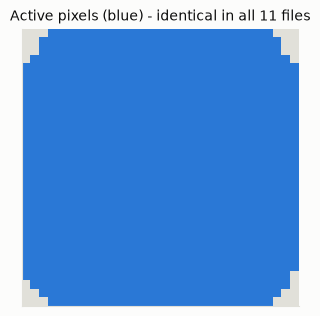

In [5]:
print(res["active_pixels"].value_counts().rename("recordings with this many active pixels"))
active = cache["patient02.bin"]["pix_active"]
fig, ax = plt.subplots(figsize=(3.6, 3.6))
ax.imshow(active, cmap=ListedColormap([GRID, BLUE]), interpolation="nearest")
ax.set_title("Active pixels (blue) - identical in all 11 files", fontsize=10)
ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.show()

## 4. Respiratory and heart rate from the pixels

An adaptive cardiac filter needs both rates. I tried eitprocessing `RateDetection` (Welch spectrum of the global
signal for RR; HR from the pixels where the cardiac component weighs more) and checked RR against the device
breath markers.

- RR agrees with the device markers within 1.7 breaths/min in every file.
- HR is wrong in two files: `rec02` gives 41.5/min and `rec03` exactly 40.0/min, which is the lower limit of the
  adult search range. Patient 01 is at 62-118/min in the other recordings.
- Looking at the spectrum of `rec03` (right plot below), there is a clear peak near 107/min, matching the heart
  rate of the same patient in the other recordings. The heart rate *is* in the data; the estimator picked the
  wrong maximum, the edge of the range on the slope of the respiratory peak.

So the HR estimate is not reliable enough to drive a filter on its own. What I do instead is in §5c.

In [6]:
rates = res[["rr_spectrum", "rr_device_flags", "hr_spectrum"]].copy()
rates["rr_difference"] = rates.rr_spectrum - rates.rr_device_flags
rates["hr_at_range_edge"] = rates.hr_spectrum < 42
rates

,rr_spectrum,rr_device_flags,hr_spectrum,rr_difference,hr_at_range_edge
file,,,,,
01_Healthy_Lung_01.bin,10.24,10.73,64.07,-0.49,False
patient01_rec02.bin,30.18,30.00,41.47,0.18,True
patient01_rec03.bin,30.25,29.74,40.00,0.51,True
patient01_rec04.bin,30.67,31.47,108.18,-0.80,False
patient01_rec05.bin,29.34,27.65,87.70,1.69,False
patient01_rec07.bin,31.25,30.45,62.18,0.80,False
patient01_rec09.bin,30.08,28.75,106.47,1.33,False
patient01_rec11.bin,33.66,33.07,112.56,0.58,False
patient01_rec12.bin,41.69,40.45,118.44,1.24,False


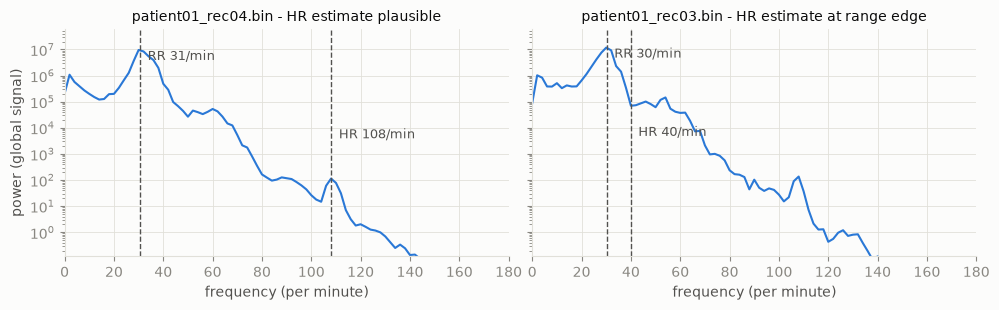

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for ax, name, label in zip(axes, ["patient01_rec04.bin", "patient01_rec03.bin"], ["HR estimate plausible", "HR estimate at range edge"]):
    c = cache[name]
    f, p = signal.welch(c["g"] - c["g"].mean(), c["fs"], nperseg=int(30 * c["fs"]))
    ax.semilogy(f * 60, p, color=BLUE)
    for value, text, height in [(c["rr"] * 60, "RR", 1.0), (c["hr"] * 60, "HR", 1e-3)]:
        ax.axvline(value, color=INK2, linestyle="--", linewidth=1)
        ax.text(value + 3, p.max() * height, f"{text} {value:.0f}/min", color=INK2, fontsize=9, va="top")
    ax.set_xlim(0, 180); ax.set_ylim(p.max() * 1e-8, p.max() * 5)
    ax.set_xlabel("frequency (per minute)")
    ax.set_title(f"{name} - {label}", fontsize=10)
axes[0].set_ylabel("power (global signal)")
plt.tight_layout(); plt.show()

## 5. Which cardiac filter?

I compared two options on the global signal:

- a Butterworth low-pass (4th order, zero phase) with the cutoff halfway between RR and HR;
- the multiple digital notch filter (MDN; Wisse et al., Physiol Meas 2024, DOI: 10.1088/1361-6579/ad46e3),
  using the eitprocessing implementation: one band-stop around each cardiac harmonic, then a low-pass at 220/min.

For each file I measured how much of the tidal variation survives (median TIV after filtering as % of the
unfiltered one, measured at the *device* breath markers so that it does not depend on my own processing) and how
much cardiac power is removed (dB around HR).

My patients breathe fast, 28-42/min (0.5-0.7 Hz). A low-pass between RR and HR also cuts the harmonics of the
breathing: with a correct HR the Butterworth keeps 87-100 % of the TIV, worst when HR is close to RR (`patient02`,
`rec07`). The MDN keeps 99-101 % and removes more cardiac power (-33 to -45 dB against -13 to -35 dB). When the HR
estimate is wrong (`rec02`, `rec03`) neither filter works, and the Butterworth loses a quarter of the TIV - one
more reason to check the HR first.

Both filters depend on the heart rate, and §4 showed I cannot trust the estimate. Next question: what does a wrong
heart rate cost?

In [8]:
res[["rr_spectrum", "hr_spectrum", "cutoff_Hz", "tiv_kept_butterworth_pct", "tiv_kept_mdn_pct", "cardiac_dB_butterworth", "cardiac_dB_mdn"]]

,rr_spectrum,hr_spectrum,cutoff_Hz,tiv_kept_butterworth_pct,tiv_kept_mdn_pct,cardiac_dB_butterworth,cardiac_dB_mdn
file,,,,,,,
01_Healthy_Lung_01.bin,10.24,64.07,0.62,100.50,101.39,-35.40,-43.28
patient01_rec02.bin,30.18,41.47,0.60,76.37,97.35,-9.65,-3.94
patient01_rec03.bin,30.25,40.00,0.59,70.61,92.37,-5.32,-1.70
patient01_rec04.bin,30.67,108.18,1.16,99.23,100.21,-31.17,-40.46
patient01_rec05.bin,29.34,87.70,0.98,99.32,100.17,-26.95,-34.61
patient01_rec07.bin,31.25,62.18,0.78,93.48,99.23,-18.69,-44.58
patient01_rec09.bin,30.08,106.47,1.14,99.42,100.17,-31.08,-43.78
patient01_rec11.bin,33.66,112.56,1.22,99.48,99.73,-30.43,-45.08
patient01_rec12.bin,41.69,118.44,1.33,99.02,99.99,-27.74,-44.79


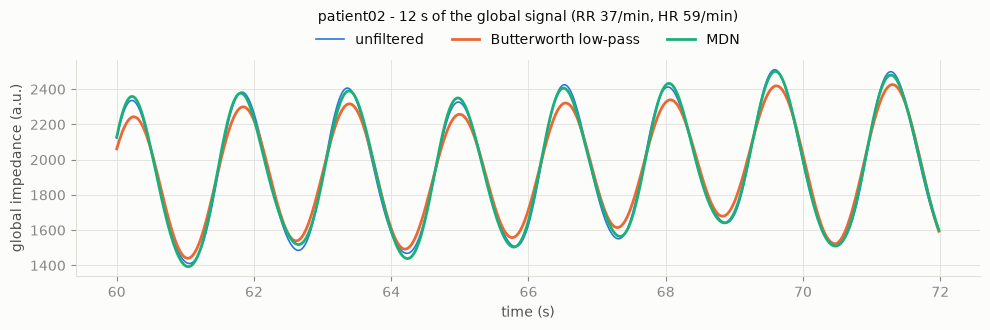

In [9]:
c = cache["patient02.bin"]
t = np.arange(len(c["g"])) / c["fs"]
win = (t >= 60) & (t < 72)
fig, ax = plt.subplots(figsize=(10, 3.4))
for y, color, label in [(c["g"], BLUE, "unfiltered"), (c["g_bw"], ORANGE, "Butterworth low-pass"), (c["g_mdn"], AQUA, "MDN")]:
    ax.plot(t[win], y[win], color=color, label=label, linewidth=2 if label != "unfiltered" else 1.2)
ax.set_xlabel("time (s)"); ax.set_ylabel("global impedance (a.u.)")
ax.set_title("patient02 - 12 s of the global signal (RR 37/min, HR 59/min)", fontsize=10, pad=28)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
plt.tight_layout(); plt.show()

### 5b. What if the heart rate is wrong?

I ran the whole chain (filter → breath detection → watershed mask) with the MDN at the estimated HR and at 60, 90
and 120/min, plus two variants with no cardiac filter: nothing at all, and the 5-point moving average my colleague
used in MATLAB (`smooth`), here as a 0.1 s window. For each variant I compare with the estimated-HR run: breaths
found, agreement with the device markers, median TIV, lung mask (Dice) and GI.

In [10]:
def moving_average(x, seconds, fs, axis=0):
    # Centred moving average over `seconds` (odd number of samples), like MATLAB smooth().
    n = max(1, int(round(seconds * fs)) // 2 * 2 + 1)
    return ndimage.uniform_filter1d(x, size=n, axis=axis, mode="nearest")


def run_chain(eit, pix_filtered):
    eit_x = copy.deepcopy(eit)
    eit_x.pixel_impedance = pix_filtered
    breaths = BreathDetection().find_breaths(eit_x.get_summed_impedance()).values
    idx = np.array([np.searchsorted(eit.time, [b.start_time, b.middle_time, b.end_time]) for b in breaths])
    captured = {}
    mask = as_bool(WatershedLungspace(threshold_fraction=THRESHOLD).apply(eit_x, captures=captured))
    tidal = captured["mean tiv"].values
    lung = tidal[mask]
    g = pix_filtered.sum(axis=(1, 2))
    return dict(idx=idx, peaks_t=np.array([b.middle_time for b in breaths]) - eit.time[0], mask=mask,
                tiv=np.median(g[idx[:, 1]] - g[idx[:, 0]]),
                gi=np.abs(lung - np.median(lung)).sum() / np.abs(lung).sum())


from scipy import ndimage

rows, variability_inputs = [], {}
for path in FILES:
    ours = load_data(path)
    eit = next(iter(load_eit_data(path, vendor="draeger").eit_data.values()))
    fs, pix = eit.sample_frequency, np.asarray(eit.pixel_impedance, dtype=float)
    dev_t = np.flatnonzero(np.asarray(ours.min_max_flags) == 1) / fs
    rr, hr_est = res.loc[path.name, "rr_spectrum"] / 60, res.loc[path.name, "hr_spectrum"] / 60
    variants = {"MDN estimated HR": hr_est, "MDN 60/min": 1.0, "MDN 90/min": 1.5, "MDN 120/min": 2.0,
                "no filter": None, "moving average 0.1 s": "ma"}
    out = {}
    for name, hr in variants.items():
        if hr is None:
            pf = pix
        elif hr == "ma":
            pf = moving_average(pix, 0.1, fs)
        elif hr <= 1.05 * rr:
            continue  # MDN refuses a heart rate at or below the respiratory rate
        else:
            pf = MDNFilter(respiratory_rate=rr, heart_rate=hr).apply(pix, sample_frequency=fs, axis=0)
        out[name] = run_chain(eit, pf)
        out[name]["pf_global"] = pf.sum(axis=(1, 2))
        out[name]["pf_halves"] = (pf[:, :16].sum(axis=(1, 2)), pf[:, 16:].sum(axis=(1, 2)))
    base = out["MDN estimated HR"]
    for name, o in out.items():
        rows.append({"file": path.name, "variant": name, "hr_over_rr": (variants[name] / rr) if isinstance(variants[name], float) else np.nan,
                     "breaths": len(o["idx"]), "sensitivity_vs_device": match_events(dev_t, o["peaks_t"])[0],
                     "tiv_vs_estimated_pct": 100 * o["tiv"] / base["tiv"],
                     "dice_vs_estimated": dice(o["mask"], base["mask"]), "gi_minus_estimated": o["gi"] - base["gi"]})
    variability_inputs[path.name] = (base["idx"], out)
sens = pd.DataFrame(rows)
worst = sens[sens.variant != "MDN estimated HR"].groupby("variant").agg(
    tiv_min_pct=("tiv_vs_estimated_pct", "min"), tiv_max_pct=("tiv_vs_estimated_pct", "max"),
    dice_min=("dice_vs_estimated", "min"), gi_max_abs_change=("gi_minus_estimated", lambda x: x.abs().max()))
with pd.option_context("display.precision", 3):
    display(worst)

,tiv_min_pct,tiv_max_pct,dice_min,gi_max_abs_change
variant,,,,
MDN 120/min,99.173,107.192,0.995,0.007
MDN 60/min,97.614,106.812,0.994,0.003
MDN 90/min,99.401,106.983,0.995,0.007
moving average 0.1 s,98.947,106.611,0.995,0.007
no filter,99.179,107.087,0.995,0.007


Breaths, mask and GI hardly notice which heart rate I use, or whether I filter at all: Dice ≥ 0.99 and GI within
0.01 in every case, and the breath counts are the same within one breath. The median TIV stays within about ±2.5 %,
with one exception: in `rec03` the run with the *estimated* HR (40/min, almost on top of the breathing) loses
about 7 % of the TIV compared with every other variant. A wrong heart rate far from RR costs almost nothing; a heart
rate close to RR is the harmful case, because the first notch of the MDN starts at (RR + HR) / 2 and ends up biting
the breathing itself.

Medians can hide noise, though, and the database will store every single breath. So I also looked at the
breath-to-breath variability.

In [11]:
rows = []
for name, (idx, out) in variability_inputs.items():
    r = {"file": name}
    for variant in ["no filter", "moving average 0.1 s", "MDN estimated HR"]:
        o = out[variant]
        for region, sig in [("global", o["pf_global"]), ("ventral", o["pf_halves"][0]), ("dorsal", o["pf_halves"][1])]:
            tiv = sig[idx[:, 1]] - sig[idx[:, 0]]
            r[(region, variant)] = 100 * tiv.std() / tiv.mean()
    rows.append(r)
cv = pd.DataFrame(rows).set_index("file")
cv.columns = pd.MultiIndex.from_tuples(cv.columns)
cv.round(1)

,global,ventral,dorsal,global,ventral,dorsal,global,ventral,dorsal
,no filter,no filter,no filter,moving average 0.1 s,moving average 0.1 s,moving average 0.1 s,MDN estimated HR,MDN estimated HR,MDN estimated HR
file,,,,,,,,,
01_Healthy_Lung_01.bin,5.0,6.0,4.2,5.0,6.0,4.2,5.1,6.1,4.2
patient01_rec02.bin,10.1,7.0,16.1,10.2,7.0,16.2,14.4,14.2,17.0
patient01_rec03.bin,10.6,10.6,13.5,10.6,10.7,13.5,19.3,19.5,20.8
patient01_rec04.bin,12.4,12.1,15.1,12.4,12.1,15.1,12.3,12.1,15.1
patient01_rec05.bin,18.8,15.3,24.5,18.8,15.4,24.6,18.8,15.3,24.5
patient01_rec07.bin,17.1,12.8,25.4,17.2,12.8,25.5,17.2,12.8,25.5
patient01_rec09.bin,14.6,11.9,20.1,14.6,11.9,20.2,14.6,11.9,20.1
patient01_rec11.bin,11.8,12.2,15.5,11.9,12.3,15.6,11.8,12.2,15.5


Coefficient of variation of the breath-by-breath TIV (%), global and for the ventral and dorsal halves, all on the
same breath timing:

- with a plausible HR the MDN changes almost nothing: the variability is the same as with no filter within
  0.1 percentage points, globally and in the ventral half too, where the heart is. The largest change is in
  `patient02`, where it goes *up* a little (global 13.3 % → 14.5 %). In these images the cardiac component is tiny (well below the
  breathing in the spectrum). I suspect the Dräger software already filters the exported images - the `.asc` export
  header has "LP/BP-filter" fields - but I cannot check it without `.asc` files;
- with the HR estimated too close to RR (`rec02`, `rec03`) the MDN makes the variability much worse (`rec02`
  global 10.1 % → 14.4 %, `rec03` 10.6 % → 19.3 %): it adds noise instead of removing it;
- my colleague's moving average behaves like no filter: same breaths, same mask, and the same variability within
  0.2 percentage points.

### 5c. Decision

I keep it simple and do **not** estimate the heart rate:

- **heart rate entered manually** (I know it from the monitor) → MDN with that HR; the respiratory rate for the MDN
  comes from the spectrum, which agrees with the device markers within 1.7/min (§4);
- **no heart rate** → my colleague's moving average, defined as **0.1 s** instead of 5 samples (5 samples are 0.1 s at
  50 Hz but 0.25 s at 20 Hz), and the log says clearly that the cardiac component was *not* removed.

Why it is acceptable: on these recordings not filtering was never meaningfully worse than filtering (at most 0.1
percentage points of variability, §5b), while the estimated HR was wrong in a harmful way in 2 of 11 files. Why I keep the MDN for the manual case: on other data
(Timpel, other patients, less smoothed images) the heart may weigh more, and with a correct HR the MDN costs nothing.

Limits: two patients and one volunteer, no ECG reference, no PEEP trial. To recheck with more recordings, especially
Timpel files with the `qrs_flag`.

Note: sections 6 and 7 were done before this decision, with the MDN at the estimated HR. §5b shows that breaths,
mask and GI do not depend on that choice, so I left them as they were.

## 6. Can I trust the device breath markers?

The PulmoVista writes its own breath markers in the `.bin` (`min_max_flag`, +1 at end-inspiration). If they are
reliable they are useful twice: as a breath-detection method and as a reference to check other methods.
I compared them with eitprocessing `BreathDetection` run on the MDN-filtered global signal, counting a match
when the two peaks are within 0.5 s.

- All detected breaths but one have a device marker next to them (PPV ≥ 0.99).
- 80-99 % of the device markers are matched; the missing ones are mostly the first and last breath, which the
  algorithm drops on purpose because they are incomplete.
- The median timing difference is at most 0.06 s (3 frames at 50 Hz), and 0 in six files.

Good enough to keep the device markers as a method (`device_flags`) and as a reference.

In [12]:
res[["breaths_detected", "breaths_device", "sensitivity", "ppv", "median_offset_s"]].round(3)

,breaths_detected,breaths_device,sensitivity,ppv,median_offset_s
file,,,,,
01_Healthy_Lung_01.bin,8,10,0.80,1.00,0.00
patient01_rec02.bin,14,16,0.88,1.00,0.06
patient01_rec03.bin,55,57,0.96,1.00,0.02
patient01_rec04.bin,117,118,0.98,0.99,0.00
patient01_rec05.bin,104,106,0.98,1.00,0.00
patient01_rec07.bin,100,102,0.98,1.00,0.02
patient01_rec09.bin,68,69,0.99,1.00,0.00
patient01_rec11.bin,89,91,0.98,1.00,0.05
patient01_rec12.bin,88,89,0.99,1.00,0.00


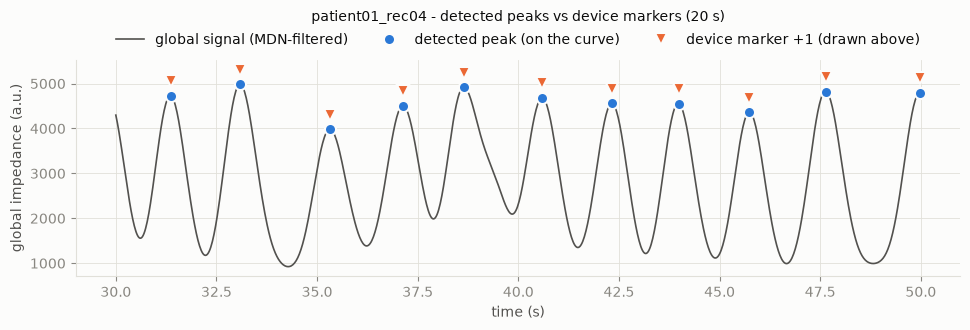

In [13]:
c = cache["patient01_rec04.bin"]
t = np.arange(len(c["g_f"])) / c["fs"]
win = (t >= 30) & (t < 50)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(t[win], c["g_f"][win], color=INK2, linewidth=1.2, label="global signal (MDN-filtered)")
lift = 0.08 * np.ptp(c["g_f"][win])  # device markers drawn just above the peak so both stay visible
for times, color, marker, dy, label in [(c["det_peaks_t"], BLUE, "o", 0, "detected peak (on the curve)"),
                                        (c["dev_peaks_t"], ORANGE, "v", lift, "device marker +1 (drawn above)")]:
    sel = times[(times >= 30) & (times < 50)]
    ax.plot(sel, np.interp(sel, t, c["g_f"]) + dy, linestyle="none", marker=marker, markersize=8,
            color=color, markeredgecolor=SURFACE, markeredgewidth=1.5, label=label)
ax.set_xlabel("time (s)"); ax.set_ylabel("global impedance (a.u.)")
ax.set_title("patient01_rec04 - detected peaks vs device markers (20 s)", fontsize=10, pad=28)
ax.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=3)
plt.tight_layout(); plt.show()

## 7. Lung mask: which eitprocessing method?

The `.bin` has no lung mask (§3), so I need to compute one. eitprocessing offers three methods in its `roi` module,
all with a default threshold of 15 % of the maximum, and I tried all three:

- `TIVLungspace`: each pixel is measured at the start and end of inspiration of the **global** signal (its tidal
  variation, TIV), averaged over the breaths; pixels above 15 % of the maximum are lung.
- `AmplitudeLungspace`: the same, but each pixel is measured at **its own** start and end of inspiration. The authors
  do not recommend it on its own, because it can include reconstruction artifacts.
- `WatershedLungspace`: combines the two. It was designed for pendelluft: a pixel that inflates late looks small at
  the global timing and is missed by the TIV method.

In [14]:
res[["px_tiv", "px_amplitude", "px_watershed"]]

,px_tiv,px_amplitude,px_watershed
file,,,
01_Healthy_Lung_01.bin,511,512,512
patient01_rec02.bin,368,395,372
patient01_rec03.bin,371,388,381
patient01_rec04.bin,353,365,369
patient01_rec05.bin,367,367,370
patient01_rec07.bin,351,356,356
patient01_rec09.bin,351,371,373
patient01_rec11.bin,374,429,391
patient01_rec12.bin,335,405,381


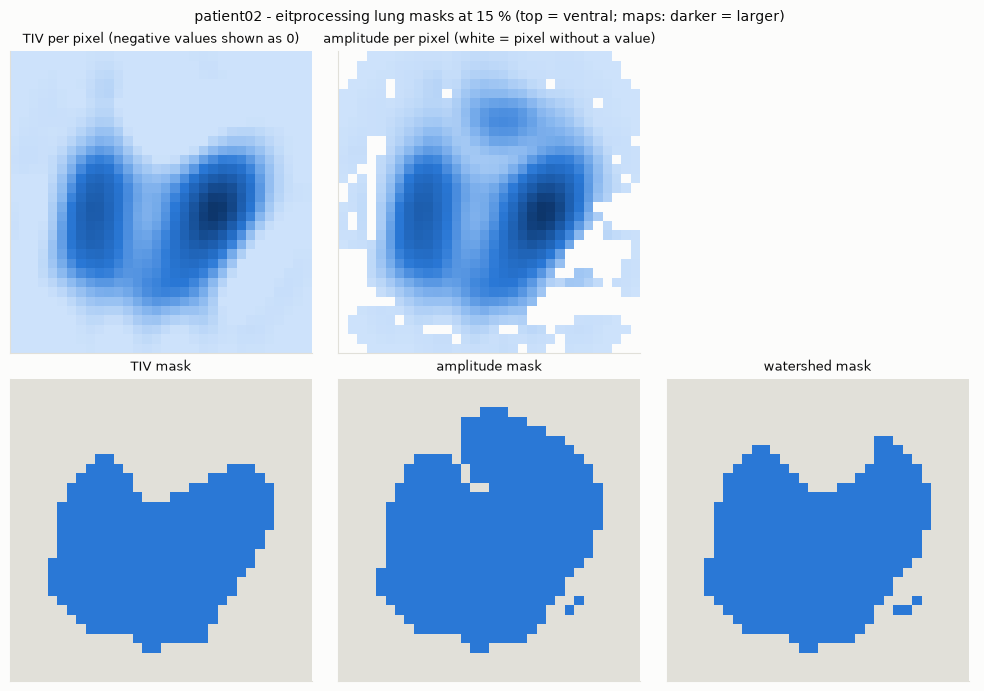

In [15]:
c = cache["patient02.bin"]
panels = [
    (np.clip(c["tiv_map"], 0, None), SEQ, "TIV per pixel (negative values shown as 0)"),
    (c["amp_map"], SEQ, "amplitude per pixel (white = pixel without a value)"), (None, None, ""),
    (c["tiv_mask"], ListedColormap([GRID, BLUE]), "TIV mask"),
    (c["amplitude_mask"], ListedColormap([GRID, BLUE]), "amplitude mask"),
    (c["watershed"], ListedColormap([GRID, BLUE]), "watershed mask"),
]
fig, axes = plt.subplots(2, 3, figsize=(10, 7))
for ax, (img, cmap, title) in zip(axes.ravel(), panels):
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    if img is None:
        ax.axis("off"); continue
    ax.imshow(img, cmap=cmap, interpolation="nearest")
    ax.set_title(title, fontsize=9)
fig.suptitle("patient02 - eitprocessing lung masks at 15 % (top = ventral; maps: darker = larger)", fontsize=10)
plt.tight_layout(); plt.show()

The amplitude mask takes up to 84 pixels more than the TIV mask, and in the `patient02` maps it also picks up a ventral
region between the lungs (probably heart or vessels). The watershed takes 1 to 49 pixels more than the TIV mask, and
leaves that ventral region out.

**Decision:** watershed at 15 %, as in eitprocessing.

### 7b. Reimplementing the eitprocessing watershed

I do not want fastEIT to depend on eitprocessing for this step, so I rewrote it in my own code **following the
eitprocessing implementation** (v1.8.8: `WatershedLungspace`, which uses `TIV` and `PixelBreath` in "phase shift"
mode). These are their steps:

1. **TIV map**: for each breath of the global signal, pixel value at the global end of inspiration minus the value at
   the global start; mean over the breaths.
2. **Amplitude map**, pixel by pixel:
   - remove the linear trend from the global signal and from the pixel signal;
   - estimate the delay of the pixel with a cross-correlation (shifts within ± one mean breath duration; the clear
     positive peak closest to zero);
   - shift the global end-inspiration times by that delay; between two shifted times take the pixel minimum (its
     start of inspiration), between two minima its maximum;
   - amplitude = maximum - starting minimum; the first and last breath are dropped, and a pixel that loses more than
     25 % of its breaths is dropped;
   - mean over the same breaths used for the TIV map.
3. **Threshold**: 15 % of the maximum of the TIV map; the same value is applied to the amplitude map.
4. **Watershed**: the amplitude map is split into regions around its local maxima; a region is kept if its maximum
   lies inside the TIV mask. The mask is the kept regions within the amplitude mask.

In [16]:
from scipy import ndimage

MAX_SKIPPED_FRACTION = 0.25


def pixel_lag(global_detrended, pixel_detrended, max_lag):
    # Step 2: delay (samples) of the cross-correlation peak closest to zero within ±max_lag; None if no peak.
    n = len(global_detrended)
    xcorr = signal.correlate(global_detrended, pixel_detrended, mode="same")
    lags = signal.correlation_lags(n, n, mode="same")
    window = np.abs(lags) <= max_lag
    peaks, _ = signal.find_peaks(xcorr[window], height=0, prominence=xcorr.std())
    if len(peaks) == 0:
        return None
    candidates = lags[window][peaks]
    closest = candidates[np.abs(candidates) == np.abs(candidates).min()]
    if len(closest) == 1:
        return int(closest[0])
    return int(closest[np.argmax(xcorr[np.searchsorted(lags, closest)])])


def pixel_amplitudes(pix, global_signal, global_peaks):
    # Step 2: amplitude of each pixel in each breath, on the pixel's own timing. First and last breath stay NaN.
    n_frames, n_rows, n_cols = pix.shape
    out = np.full((len(global_peaks), n_rows, n_cols), np.nan)
    global_detrended = signal.detrend(global_signal, type="linear")
    max_lag = np.mean(np.diff(global_peaks))
    for r in range(n_rows):
        for c in range(n_cols):
            y = pix[:, r, c]
            if np.std(y) == 0:
                continue
            lag = pixel_lag(global_detrended, signal.detrend(y, type="linear"), max_lag)
            if lag is None:
                continue
            expected = global_peaks - lag
            skip = set(np.flatnonzero((expected < 0) | (expected >= n_frames)))
            expected = np.clip(expected, 0, n_frames - 1)
            valleys = np.array([a + np.argmin(y[a:b]) for a, b in zip(expected[:-1], expected[1:])])
            starts, ends = valleys[:-1], valleys[1:]
            tops = np.array([a + np.argmax(y[a:b]) for a, b in zip(starts, ends)])
            skip |= set(np.flatnonzero((starts >= tops) | (tops >= ends)))
            if len(starts) > len(skip) > len(starts) * MAX_SKIPPED_FRACTION:
                continue
            amplitude = y[tops] - y[starts]
            amplitude[[i for i in skip if i < len(amplitude)]] = np.nan
            out[1:-1, r, c] = amplitude
    return out


def watershed_mask(pix, breaths_idx, threshold=THRESHOLD):
    # Steps 1-4. Returns the mean TIV map, the mean amplitude map and the mask.
    starts = np.array([s for s, _, _ in breaths_idx])
    peaks = np.array([p for _, p, _ in breaths_idx])
    tiv_per_breath = pix[peaks] - pix[starts]
    amp_per_breath = pixel_amplitudes(pix, pix.sum(axis=(1, 2)), peaks)
    used = ~np.all(np.isnan(tiv_per_breath), axis=(1, 2)) & ~np.all(np.isnan(amp_per_breath), axis=(1, 2))
    mean_tiv = np.nanmean(tiv_per_breath[used], axis=0)
    mean_amp = np.nanmean(amp_per_breath[used], axis=0)
    thr = threshold * np.nanmax(mean_tiv)
    tiv_mask, amp_mask = mean_tiv >= thr, mean_amp >= thr
    peak_xy = feature.peak_local_max(np.nan_to_num(mean_amp), exclude_border=False)
    peak_map = np.zeros(mean_amp.shape, bool)
    peak_map[tuple(peak_xy.T)] = True
    markers, _ = ndimage.label(peak_map)
    kept = np.unique(markers[peak_map & tiv_mask])
    regions = segmentation.watershed(-mean_amp, markers)
    return mean_tiv, mean_amp, np.isin(regions, kept) & amp_mask

Now the check on every recording: my mask against `WatershedLungspace`, and my two intermediate maps against the ones
eitprocessing returns through `captures`. In the same loop I also tried a shortcut for step 2 (max - min of each pixel
inside each breath, without estimating the delay), to see whether all this work is needed. I compare the two on the
global inhomogeneity index GI = Σ|DI - median(DI)| / Σ|DI| over the lung pixels (Zhao et al., Intensive Care Med 2009,
DOI: 10.1007/s00134-009-1589-y).

In [17]:
def prepare(path):
    eit = next(iter(load_eit_data(path, vendor="draeger").eit_data.values()))
    fs, pix = eit.sample_frequency, np.asarray(eit.pixel_impedance, dtype=float)
    rr, hr = RateDetection("adult").apply(eit, suppress_length_warnings=True, suppress_edge_case_warning=True)
    eit_f = copy.deepcopy(eit)
    eit_f.pixel_impedance = MDNFilter(respiratory_rate=rr, heart_rate=hr).apply(pix, sample_frequency=fs, axis=0)
    breaths = BreathDetection().find_breaths(eit_f.get_summed_impedance()).values
    idx = [tuple(np.searchsorted(eit.time, [b.start_time, b.middle_time, b.end_time])) for b in breaths]
    return eit_f, np.asarray(eit_f.pixel_impedance, dtype=float), idx


def shortcut_mask(pix, breaths_idx, mean_tiv, threshold=THRESHOLD):
    # Step 2 replaced by max - min inside each breath; steps 3-4 unchanged.
    mean_amp = np.mean([pix[s:e].max(axis=0) - pix[s:e].min(axis=0) for s, _, e in breaths_idx], axis=0)
    thr = threshold * np.nanmax(mean_tiv)
    peak_xy = feature.peak_local_max(mean_amp, exclude_border=False)
    peak_map = np.zeros(mean_amp.shape, bool)
    peak_map[tuple(peak_xy.T)] = True
    markers, _ = ndimage.label(peak_map)
    kept = np.unique(markers[peak_map & (mean_tiv >= thr)])
    return np.isin(segmentation.watershed(-mean_amp, markers), kept) & (mean_amp >= thr)


def gi(tidal_image, mask):
    lung = tidal_image[mask]
    return np.abs(lung - np.median(lung)).sum() / np.abs(lung).sum()


rows = []
for path in FILES:
    eit_f, pix_f, idx = prepare(path)
    captured = {}
    reference = as_bool(WatershedLungspace(threshold_fraction=THRESHOLD).apply(eit_f, captures=captured))
    mean_tiv, mean_amp, mine = watershed_mask(pix_f, idx)
    shortcut = shortcut_mask(pix_f, idx, mean_tiv)
    rows.append({
        "file": path.name,
        "px_eitprocessing": int(reference.sum()), "px_mine": int(mine.sum()), "px_differ": int((reference != mine).sum()),
        "max_map_difference": max(np.nanmax(np.abs(mean_tiv - captured["mean tiv"].values)),
                                  np.nanmax(np.abs(mean_amp - captured["mean amplitude"].values))),
        "px_shortcut": int(shortcut.sum()), "gi_mine": gi(mean_tiv, mine), "gi_shortcut": gi(mean_tiv, shortcut),
    })
check = pd.DataFrame(rows).set_index("file")
with pd.option_context("display.precision", 3):
    display(check)

,px_eitprocessing,px_mine,px_differ,max_map_difference,px_shortcut,gi_mine,gi_shortcut
file,,,,,,,
01_Healthy_Lung_01.bin,512,512,0,0.000e+00,512,0.374,0.374
patient01_rec02.bin,372,372,0,5.329e-15,382,0.376,0.392
patient01_rec03.bin,381,381,0,1.066e-14,401,0.429,0.456
patient01_rec04.bin,369,369,0,1.421e-14,381,0.423,0.438
patient01_rec05.bin,370,370,0,1.421e-14,372,0.369,0.372
patient01_rec07.bin,356,356,0,8.882e-15,359,0.361,0.365
patient01_rec09.bin,373,373,0,1.066e-14,387,0.450,0.465
patient01_rec11.bin,391,391,0,1.066e-14,421,0.477,0.510
patient01_rec12.bin,381,381,0,1.066e-14,414,0.523,0.562


My masks are identical to the eitprocessing ones in every recording, and the intermediate maps differ by about 1e-14
at most, which is just floating-point rounding.

The shortcut is not good enough: it takes up to 33 pixels more and raises GI in every patient recording, by up to
about 0.04. GI is one of the indices I want to report, so I keep the full method.

**Decision:** lung mask = watershed at 15 % of the maximum TIV, following the eitprocessing steps, reimplemented in
fastEIT and checked against eitprocessing v1.8.8 as above.

## 8. Breath detection and quality flags

For the breath detection I follow the eitprocessing `BreathDetection` (v1.8.8) and rewrite it in my own code, as for
the lung mask. The only change I want: eitprocessing **removes** the breaths close to invalid data, while I keep them
in the breath table with a flag, so that I decide what to do with them.

In practice my analyses will be done on stable phases that I select with segments, also when the patient breathes
spontaneously, so the breaths I analyse will mostly be regular. The flags are a safety net for what slips through,
not the main selection.

These are the eitprocessing steps, on the global signal (here smoothed with the 0.1 s moving average of §5c):

1. **Invalid data**: values beyond mean ± 4 × (distance between the mean and the 5th / 95th percentile) are invalid;
   for the detection they are replaced by the nearest valid value.
2. **Moving average** over 15 s (Blackman window), used as a local height threshold: a peak must be above it, a valley
   below it. This is what makes the detection follow EELI changes.
3. **Peaks and valleys** with `scipy.signal.find_peaks`, at least 2/3 s apart.
4. **Edges**: the first or last valley is dropped if the signal before or after it never rises above the moving
   average; peaks outside the first and last valley are dropped.
5. **Doubles**: between two valleys only the highest peak is kept, between two peaks only the lowest valley.
6. **Low amplitude**: peaks with an amplitude below 25 % of the median are removed and step 5 is repeated, so a tiny
   peak is merged into the breath around it.
7. **Breaths** = valley, peak, valley.
8. Breaths within 0.5 s of invalid data are removed. **Here I flag them instead.**

In [18]:
import math

from scipy.signal import find_peaks


def invalid_indices(x, percentile=5, multiplier=4):
    # Step 1.
    mean = np.mean(x)
    low = mean - (mean - np.percentile(x, percentile)) * multiplier
    high = mean + (np.percentile(x, 100 - percentile) - mean) * multiplier
    return np.flatnonzero((x < low) | (x > high))


def fill_nearest(x):
    # Step 1: each NaN takes the nearest valid value (the earlier one when equally far).
    x = np.copy(x)
    nan = np.flatnonzero(np.isnan(x))
    if not len(nan):
        return x
    for group in np.split(nan, np.flatnonzero(np.diff(nan) != 1) + 1):
        if group[0] == 0:
            x[group] = x[group[-1] + 1]
        elif group[-1] == len(x) - 1:
            x[group] = x[group[0] - 1]
        else:
            half = len(group) // 2
            x[group[:half]], x[group[half:]] = x[group[0] - 1], x[group[-1] + 1]
    return x


def blackman_moving_average(x, seconds, fs):
    # Step 2.
    n = int(fs * seconds)
    n += 1 - n % 2
    if n > len(x):
        n = int((len(x) - 1) / 2) * 2 + 1
    weights = np.blackman(n)
    weights /= weights.sum()
    return np.convolve(np.pad(x, (n - 1) // 2, mode="edge"), weights, mode="valid")


def drop_doubles(x, peaks, valleys):
    # Step 5: one peak between two valleys, one valley between two peaks.
    peaks, valleys = list(peaks), list(valleys)
    i = 0
    while i < len(valleys) - 1:
        between = [k for k, p in enumerate(peaks) if valleys[i] < p < valleys[i + 1]]
        if not between:
            del valleys[i if x[valleys[i]] > x[valleys[i + 1]] else i + 1]
            continue
        if len(between) > 1:
            a, b = between[0], between[1]
            del peaks[a if x[peaks[a]] < x[peaks[b]] else b]
            continue
        i += 1
    return np.array(peaks, dtype=int), np.array(valleys, dtype=int)


def detect_breaths(x, fs, min_duration=2 / 3, window=15, low_amplitude=0.25, invalid_window=0.5):
    # Steps 1-8. Returns (start, peak, end) indices and a flag for breaths close to invalid data.
    invalid = invalid_indices(x)
    data = np.copy(x).astype(float)
    data[invalid] = np.nan
    data = fill_nearest(data)
    ma = blackman_moving_average(data, window, fs)
    distance = max(min_duration * fs, 1)
    peaks, _ = find_peaks(data, distance=distance, height=ma)
    valleys, _ = find_peaks(-data, distance=distance, height=-ma)
    if len(valleys) < 2 or len(peaks) < 1:
        return np.empty((0, 3), int), np.empty(0, bool)
    if data[: valleys[0]].max() < ma[valleys[0]]:
        valleys = valleys[1:]
    if data[valleys[-1]:].max() < ma[valleys[-1]]:
        valleys = valleys[:-1]
    peaks = peaks[(peaks > valleys[0]) & (peaks < valleys[-1])]
    peaks, valleys = drop_doubles(data, peaks, valleys)
    amplitude = (2 * data[peaks] - data[valleys[:-1]] - data[valleys[1:]]) / 2
    peaks = peaks[amplitude >= low_amplitude * np.median(amplitude)]
    peaks, valleys = drop_doubles(data, peaks, valleys)
    breaths = np.column_stack([valleys[:-1], peaks, valleys[1:]])
    w = math.ceil(invalid_window * fs)
    near_invalid = np.array([np.any((invalid >= s - w) & (invalid <= e + w)) for s, _, e in breaths], dtype=bool)
    return breaths, near_invalid

Check against eitprocessing on every recording: same input signal, and I compare start, peak and end of every breath.

In [19]:
rows, breath_inputs = [], {}
for path in FILES:
    eit = next(iter(load_eit_data(path, vendor="draeger").eit_data.values()))
    fs, pix = eit.sample_frequency, np.asarray(eit.pixel_impedance, dtype=float)
    smoothed = moving_average(pix, 0.1, fs)
    eit_s = copy.deepcopy(eit)
    eit_s.pixel_impedance = smoothed
    reference = BreathDetection().find_breaths(eit_s.get_summed_impedance()).values
    ref_idx = np.array([np.searchsorted(eit.time, [b.start_time, b.middle_time, b.end_time]) for b in reference])
    g = smoothed.sum(axis=(1, 2))
    mine, near_invalid = detect_breaths(g, fs)
    kept = mine[~near_invalid]
    rows.append({"file": path.name, "breaths_eitprocessing": len(ref_idx), "breaths_mine": len(mine),
                 "flagged_near_invalid": int(near_invalid.sum()),
                 "identical": len(kept) == len(ref_idx) and np.array_equal(kept, ref_idx)})
    breath_inputs[path.name] = (g, fs, mine, near_invalid, np.asarray(eit.time) - eit.time[0])
pd.DataFrame(rows).set_index("file")

,breaths_eitprocessing,breaths_mine,flagged_near_invalid,identical
file,,,,
01_Healthy_Lung_01.bin,9,9,0,True
patient01_rec02.bin,14,14,0,True
patient01_rec03.bin,55,55,0,True
patient01_rec04.bin,117,117,0,True
patient01_rec05.bin,104,104,0,True
patient01_rec07.bin,100,100,0,True
patient01_rec09.bin,68,68,0,True
patient01_rec11.bin,89,89,0,True
patient01_rec12.bin,88,88,0,True


Same breaths as eitprocessing in every recording, start, peak and end included. None of my recordings has invalid data,
so the flag of step 8 never fires here: these are clean recordings.

### Quality flags

On top of the detection I add my own flags. They mark a breath, they never remove it; `is_valid` is true when no flag
is set (and the breath is not inside an excluded segment).

| Flag | Rule |
|------|------|
| `flag_short`, `flag_long` | duration below 0.5 s or above 20 s |
| `flag_suspect_ti_ratio` | Ti/Ttot outside 0.2-0.6 (Ti = valley to peak of the impedance) |
| `flag_amplitude_outlier` | amplitude below 0.5× or above 2× the median of the 21 surrounding breaths |
| `flag_duration_outlier` | duration above 2× the median of the 21 surrounding breaths |
| `flag_invalid_data` | step 8 above |

I first tried a robust z-score (distance from the local median in MAD units). In my most regular recordings the MAD is
so small that a breath 15 % smaller than its neighbours already gets |z| > 3, which is normal variability, not an
artifact. Ratios to the local median read better clinically ("half or double the neighbours") and do not have this
problem. 21 breaths are about 40 s at 30 breaths/min: long enough to ignore a single event, short enough to follow a
change of PEEP.

In [20]:
def quality_flags(g, fs, breaths, near_invalid, window=21):
    start, peak, end = breaths.T
    duration = (end - start) / fs
    ti_ratio = (peak - start) / (end - start)
    amplitude = pd.Series((2 * g[peak] - g[start] - g[end]) / 2)
    local = dict(window=window, center=True, min_periods=5)
    amp_ratio = amplitude / amplitude.rolling(**local).median()
    dur_ratio = pd.Series(duration) / pd.Series(duration).rolling(**local).median()
    flags = pd.DataFrame({
        "flag_short": duration < 0.5, "flag_long": duration > 20,
        "flag_suspect_ti_ratio": (ti_ratio < 0.2) | (ti_ratio > 0.6),
        "flag_amplitude_outlier": ((amp_ratio < 0.5) | (amp_ratio > 2)).values,
        "flag_duration_outlier": (dur_ratio > 2).values,
        "flag_invalid_data": near_invalid,
    })
    flags["is_valid"] = ~flags.any(axis=1)
    return flags, amp_ratio.values, dur_ratio.values


rows, flag_cache = [], {}
for name, (g, fs, breaths, near_invalid, t) in breath_inputs.items():
    flags, amp_ratio, dur_ratio = quality_flags(g, fs, breaths, near_invalid)
    flag_cache[name] = (flags, amp_ratio, dur_ratio)
    row = {"file": name, "breaths": len(flags)}
    row.update(flags.drop(columns="is_valid").sum().astype(int).to_dict())
    row["valid"] = int(flags.is_valid.sum())
    rows.append(row)
counts = pd.DataFrame(rows).set_index("file")
counts.loc["total"] = counts.sum()
counts

,breaths,flag_short,flag_long,flag_suspect_ti_ratio,flag_amplitude_outlier,flag_duration_outlier,flag_invalid_data,valid
file,,,,,,,,
01_Healthy_Lung_01.bin,9,0,0,1,0,0,0,8
patient01_rec02.bin,14,0,0,0,0,0,0,14
patient01_rec03.bin,55,0,0,1,0,0,0,54
patient01_rec04.bin,117,0,0,2,0,0,0,115
patient01_rec05.bin,104,0,0,0,0,0,0,104
patient01_rec07.bin,100,0,0,0,0,0,0,100
patient01_rec09.bin,68,0,0,1,0,1,0,66
patient01_rec11.bin,89,0,0,1,0,0,0,88
patient01_rec12.bin,88,0,0,1,1,1,0,87


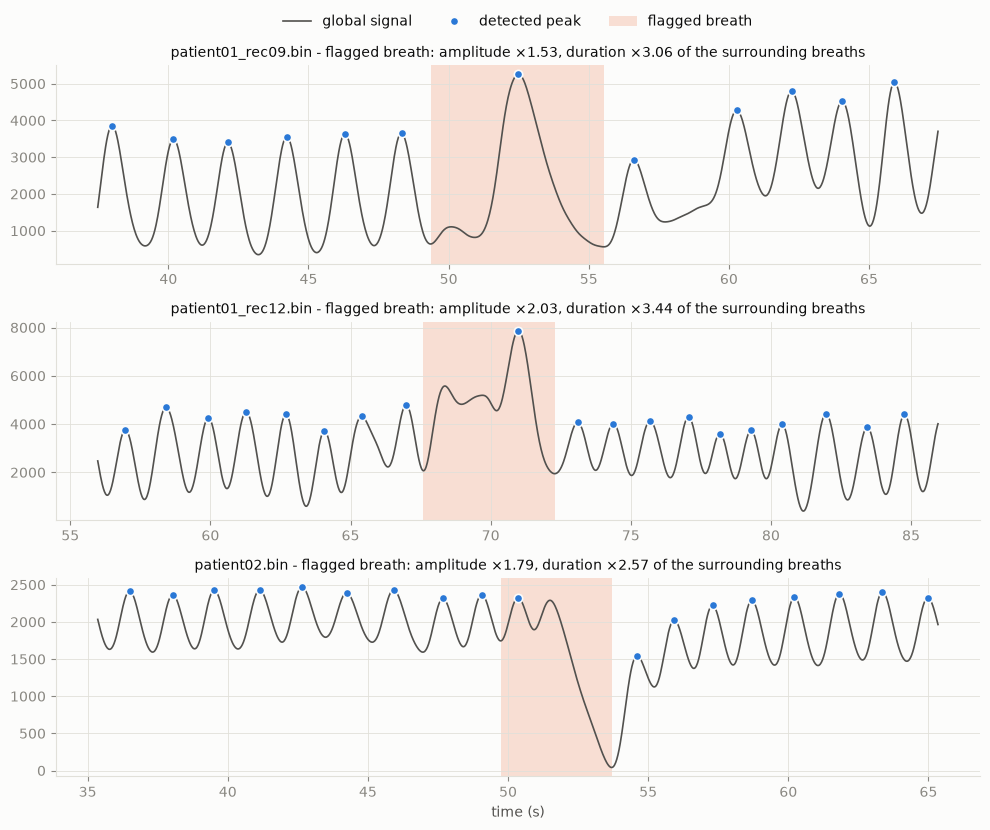

In [21]:
fig, axes = plt.subplots(3, 1, figsize=(10, 8.4))
for ax, name in zip(axes, ["patient01_rec09.bin", "patient01_rec12.bin", "patient02.bin"]):
    g, fs, breaths, _, t = breath_inputs[name]
    flags, amp_ratio, dur_ratio = flag_cache[name]
    flagged = np.flatnonzero(~flags.is_valid.values & (flags.flag_amplitude_outlier | flags.flag_duration_outlier).values)
    centre = breaths[flagged[0], 1]
    win = slice(max(0, centre - int(15 * fs)), min(len(g), centre + int(15 * fs)))
    ax.plot(t[win], g[win], color=INK2, linewidth=1.2, label="global signal")
    in_win = (breaths[:, 1] >= win.start) & (breaths[:, 1] < win.stop)
    ax.plot(t[breaths[in_win, 1]], g[breaths[in_win, 1]], "o", markersize=6, color=BLUE,
            markeredgecolor=SURFACE, markeredgewidth=1.2, label="detected peak")
    for k in flagged:
        if in_win[k]:
            ax.axvspan(t[breaths[k, 0]], t[breaths[k, 2]], color=ORANGE, alpha=0.2, linewidth=0, label="flagged breath")
    k = flagged[0]
    ax.set_title(f"{name} - flagged breath: amplitude ×{amp_ratio[k]:.2f}, duration ×{dur_ratio[k]:.2f} "
                 "of the surrounding breaths", fontsize=10)
axes[0].legend(loc="lower center", bbox_to_anchor=(0.5, 1.12), ncol=3)
axes[-1].set_xlabel("time (s)")
plt.tight_layout(); plt.show()

The amplitude and duration flags catch these three breaths, and looking at them they are real events, not detection
errors: a slow deep breath three times longer than the others (`rec09`), an irregular breath with several humps
(`rec12`), and a breath followed by a drop of the impedance well below the usual end-expiratory level (`patient02`),
which looks like a cough or an active expiration. When there are several humps between two valleys the detection keeps
the highest and makes a single long breath (step 5), which is why the duration flag catches them.

**Decision:** breath detection = the eitprocessing steps, reimplemented, with the breaths close to invalid data flagged
instead of removed; quality flags as in the table above, with `is_valid` when none is set.

Limits: 946 breaths from two patients and one volunteer, with very few events, and no PEEP trial. The thresholds are to recheck
on noisier recordings and on PEEP trials.

## 9. Regions of interest

I want every index to be available for dependent vs non-dependent lung and for right vs left lung, so I compute both
families of regions automatically, as horizontal layers and as quadrants, always inside the lung mask.

### Orientation

Dräger images are seen from the feet, like a CT slice (PulmoVista 500 instructions for use): row 0 is ventral, and the
left side of the image is the **right** side of the patient (column 0 = patient right, column 31 = patient left).
My colleague's MATLAB scripts use the same convention.

As an independent check I looked at where the signal beats with the heart (power at the heart rate, per pixel, in the
recordings where the estimated HR was plausible; used only for this check). There is a small ventral region to the
right of the image midline in the patients, and across the midline but shifted to the right in the volunteer: the
heart, anterior and on the patient's left. The larger central region is probably large vessels or lung perfusion.
Not a proof, but consistent with the convention.

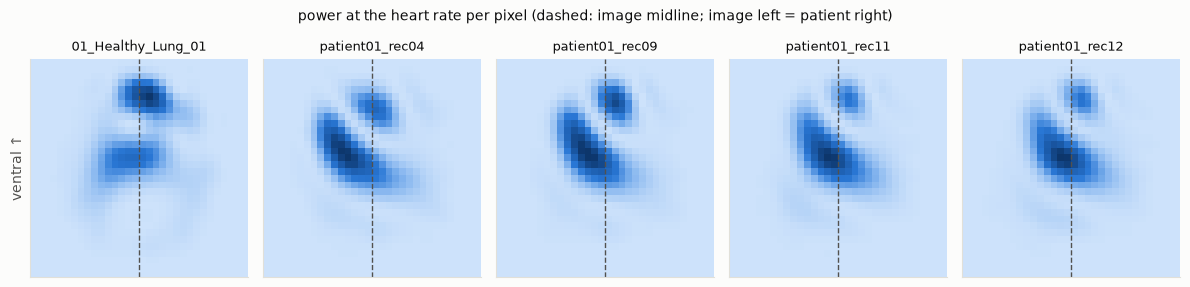

In [22]:
check_files = ["01_Healthy_Lung_01.bin", "patient01_rec04.bin", "patient01_rec09.bin", "patient01_rec11.bin", "patient01_rec12.bin"]
fig, axes = plt.subplots(1, len(check_files), figsize=(12, 3))
for ax, name in zip(axes, check_files):
    eit = next(iter(load_eit_data(TEST_FILES / name, vendor="draeger").eit_data.values()))
    fs, pix = eit.sample_frequency, np.asarray(eit.pixel_impedance, dtype=float)
    hr = res.loc[name, "hr_spectrum"] / 60
    f, p = signal.welch(pix - pix.mean(axis=0), fs, nperseg=int(30 * fs), axis=0)
    ax.imshow(p[(f > hr - 0.1) & (f < hr + 0.1)].sum(axis=0), cmap=SEQ)
    ax.axvline(15.5, color=INK2, linestyle="--", linewidth=1)
    ax.set_title(name.replace(".bin", ""), fontsize=9); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
axes[0].set_ylabel("ventral ↑", color=INK2)
fig.suptitle("power at the heart rate per pixel (dashed: image midline; image left = patient right)", fontsize=10)
plt.tight_layout(); plt.show()

### Removing small regions

Before cutting the mask into regions I remove the isolated islands smaller than 10 pixels, as eitprocessing does with
`FilterROIBySize` (minimum 10 pixels, pixels connected by their sides). I rewrote it and check it against theirs.

From here on everything uses the chain I have chosen: 0.1 s moving average (§5c), my breath detection (§8), my
watershed (§7b), small regions removed.

In [23]:
from eitprocessing.roi import PixelMask
from eitprocessing.roi.filter_by_size import FilterROIBySize


def remove_small_regions(mask, min_size=10):
    labels, n = ndimage.label(mask, structure=ndimage.generate_binary_structure(2, 1))
    sizes = ndimage.sum(mask, labels, index=np.arange(1, n + 1))
    return np.isin(labels, np.flatnonzero(sizes >= min_size) + 1)


rows, final = [], {}
for name, (g, fs, breaths, near_invalid, t) in breath_inputs.items():
    eit = next(iter(load_eit_data(TEST_FILES / name, vendor="draeger").eit_data.values()))
    smoothed = moving_average(np.asarray(eit.pixel_impedance, dtype=float), 0.1, fs)
    flags, _, _ = quality_flags(g, fs, breaths, near_invalid)
    valid = breaths[flags.is_valid.values]
    mean_tiv, _, mask = watershed_mask(smoothed, valid)
    cleaned = remove_small_regions(mask)
    reference = ~np.isnan(FilterROIBySize(min_region_size=10).apply(PixelMask(np.where(mask, 1.0, np.nan))).mask)
    final[name] = (mean_tiv, cleaned)
    rows.append({"file": name, "px_watershed": int(mask.sum()), "px_removed": int(mask.sum() - cleaned.sum()),
                 "same_as_eitprocessing": bool(np.array_equal(cleaned, reference))})
pd.DataFrame(rows).set_index("file")

,px_watershed,px_removed,same_as_eitprocessing
file,,,
01_Healthy_Lung_01.bin,517,0,True
patient01_rec02.bin,373,0,True
patient01_rec03.bin,383,0,True
patient01_rec04.bin,368,0,True
patient01_rec05.bin,371,3,True
patient01_rec07.bin,358,6,True
patient01_rec09.bin,373,1,True
patient01_rec11.bin,392,0,True
patient01_rec12.bin,383,8,True


### The regions

- **Ventral / dorsal** and the **four layers** are cut on the lung, not on the image: from the first to the last row of
  the mask, split into equal parts (the approach of my colleague's `createSummersROIs.m`; I have not found the original
  reference yet). So "dorsal" is always the dorsal part of that lung, even if the lungs sit higher or lower in the image
  from one recording to the next.
- **Right / left** are split at the midline of the image (between columns 15 and 16), the sternum-spine axis with the
  belt centred on the patient.
- **Quadrants** = ventral/dorsal × right/left.
- Every region is intersected with the lung mask.

In [24]:
def lung_regions(mask):
    rows_with_lung = np.flatnonzero(mask.any(axis=1))
    first, height = rows_with_lung[0], rows_with_lung[-1] - rows_with_lung[0] + 1
    row = np.arange(mask.shape[0])[:, None] * np.ones((1, mask.shape[1]), int)
    col = np.arange(mask.shape[1])[None, :] * np.ones((mask.shape[0], 1), int)
    layer = np.clip((row - first) * 4 // height, 0, 3)
    ventral = (row - first) * 2 < height
    right = col < mask.shape[1] // 2  # image left = patient right
    regions = {"ventral": ventral, "dorsal": ~ventral, "right": right, "left": ~right}
    regions.update({f"layer_{k + 1}": layer == k for k in range(4)})
    regions.update({"ventral_right": ventral & right, "ventral_left": ventral & ~right,
                    "dorsal_right": ~ventral & right, "dorsal_left": ~ventral & ~right})
    return {name: region & mask for name, region in regions.items()}


rows = []
for name, (mean_tiv, mask) in final.items():
    regions = lung_regions(mask)
    tidal = np.clip(mean_tiv, 0, None)
    row = {"file": name}
    for region in ["ventral", "dorsal", "right", "left", "layer_1", "layer_2", "layer_3", "layer_4"]:
        row[f"{region}_pct_tiv"] = 100 * tidal[regions[region]].sum() / tidal[mask].sum()
    rows.append(row)
pd.DataFrame(rows).set_index("file").round(1)

,ventral_pct_tiv,dorsal_pct_tiv,right_pct_tiv,left_pct_tiv,layer_1_pct_tiv,layer_2_pct_tiv,layer_3_pct_tiv,layer_4_pct_tiv
file,,,,,,,,
01_Healthy_Lung_01.bin,56.3,43.7,56.7,43.3,19.5,36.8,32.2,11.4
patient01_rec02.bin,44.6,55.4,52.4,47.6,15.6,28.9,37.2,18.3
patient01_rec03.bin,36.7,63.3,50.3,49.7,12.1,24.6,48.2,15.2
patient01_rec04.bin,40.6,59.4,54.9,45.1,11.3,29.3,47.2,12.2
patient01_rec05.bin,43.8,56.2,52.3,47.7,14.9,28.9,39.4,16.8
patient01_rec07.bin,45.9,54.1,56.8,43.2,16.5,29.5,43.7,10.4
patient01_rec09.bin,40.1,59.9,55.4,44.6,10.1,30.0,49.5,10.3
patient01_rec11.bin,51.4,48.6,48.2,51.8,7.5,43.9,40.0,8.6
patient01_rec12.bin,53.1,46.9,48.3,51.7,10.5,42.5,39.4,7.5


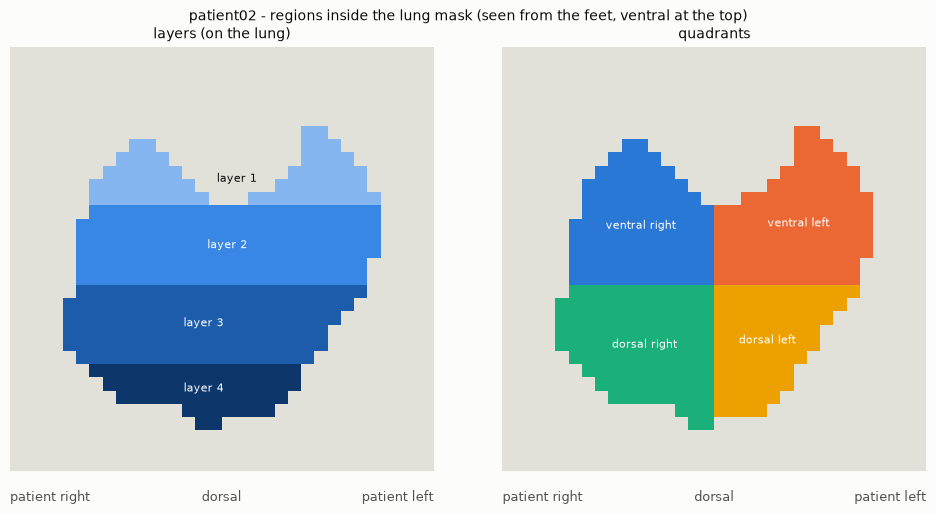

In [25]:
from matplotlib import colors as mcolors

mean_tiv, mask = final["patient02.bin"]
regions = lung_regions(mask)
layer_colors = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]
quadrant_colors = {"ventral_right": BLUE, "ventral_left": ORANGE, "dorsal_right": AQUA, "dorsal_left": "#eda100"}
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (title, items) in zip(axes, [
    ("layers (on the lung)", [(f"layer_{k + 1}", layer_colors[k], f"layer {k + 1}") for k in range(4)]),
    ("quadrants", [(n, c, n.replace("_", " ")) for n, c in quadrant_colors.items()]),
]):
    img = np.ones(mask.shape + (3,)) * np.array(mcolors.to_rgb(GRID))
    for region, color, label in items:
        img[regions[region]] = mcolors.to_rgb(color)
        r, c = np.argwhere(regions[region]).mean(axis=0)
        ax.text(c, r, label, ha="center", va="center", fontsize=8, color="white" if region != "layer_1" else INK,
                bbox=dict(facecolor="none", edgecolor="none"))
    ax.imshow(img, interpolation="nearest")
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.text(-0.5, 33, "patient right", fontsize=9, color=INK2, ha="left", va="top")
    ax.text(31.5, 33, "patient left", fontsize=9, color=INK2, ha="right", va="top")
    ax.text(15.5, 33, "dorsal", fontsize=9, color=INK2, ha="center", va="top")
fig.suptitle("patient02 - regions inside the lung mask (seen from the feet, ventral at the top)", fontsize=10)
plt.tight_layout(); plt.show()

**Decision:** small regions (< 10 pixels) removed as in eitprocessing; regions computed automatically for every
recording: ventral/dorsal halves and four layers cut on the vertical extent of the lung, right/left halves at the image
midline, four quadrants, all inside the lung mask.